In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import  seaborn as sns

In [2]:
df =pd.read_parquet("/home/anchal/os Lab/os_project/data_analyssi/ai_multicore_schedular_cleaned.parquet")

In [3]:
df.shape
df.dtypes

timestamp                  datetime64[us]
overall_cpu_utilization           float64
memory_percent                    float64
memory_used_mb                    float64
process_count                       int64
running_processes                   int64
queue_length_cpu_0                  int64
queue_length_cpu_1                  int64
queue_length_cpu_2                  int64
queue_length_cpu_3                  int64
queue_length_cpu_4                  int64
queue_length_cpu_5                  int64
queue_length_cpu_6                  int64
queue_length_cpu_7                  int64
queue_length_cpu_8                  int64
queue_length_cpu_9                  int64
queue_length_cpu_10                 int64
queue_length_cpu_11                 int64
queue_length_cpu_12                 int64
queue_length_cpu_13                 int64
queue_length_cpu_14                 int64
queue_length_cpu_15                 int64
cpu_0_utilization                 float64
cpu_1_utilization                 

In [4]:
df['task_state'].unique()

<ArrowStringArray>
['sleeping', 'idle', 'running', 'disk-sleep', 'zombie']
Length: 5, dtype: str

In [5]:
df.columns

Index(['timestamp', 'overall_cpu_utilization', 'memory_percent',
       'memory_used_mb', 'process_count', 'running_processes',
       'queue_length_cpu_0', 'queue_length_cpu_1', 'queue_length_cpu_2',
       'queue_length_cpu_3', 'queue_length_cpu_4', 'queue_length_cpu_5',
       'queue_length_cpu_6', 'queue_length_cpu_7', 'queue_length_cpu_8',
       'queue_length_cpu_9', 'queue_length_cpu_10', 'queue_length_cpu_11',
       'queue_length_cpu_12', 'queue_length_cpu_13', 'queue_length_cpu_14',
       'queue_length_cpu_15', 'cpu_0_utilization', 'cpu_1_utilization',
       'cpu_2_utilization', 'cpu_3_utilization', 'cpu_4_utilization',
       'cpu_5_utilization', 'cpu_6_utilization', 'cpu_7_utilization',
       'cpu_8_utilization', 'cpu_9_utilization', 'cpu_10_utilization',
       'cpu_11_utilization', 'cpu_12_utilization', 'cpu_13_utilization',
       'cpu_14_utilization', 'cpu_15_utilization', 'task_wait_time_delta_ms',
       'task_cpu_usage', 'task_memory_usage', 'task_runtime', 'task_

In [6]:
encoded = pd.get_dummies(
    df["task_state"] , prefix= "task_state" , dtype= int ,
)
df = pd.concat([ df , encoded] , axis= 1)
df.columns

Index(['timestamp', 'overall_cpu_utilization', 'memory_percent',
       'memory_used_mb', 'process_count', 'running_processes',
       'queue_length_cpu_0', 'queue_length_cpu_1', 'queue_length_cpu_2',
       'queue_length_cpu_3', 'queue_length_cpu_4', 'queue_length_cpu_5',
       'queue_length_cpu_6', 'queue_length_cpu_7', 'queue_length_cpu_8',
       'queue_length_cpu_9', 'queue_length_cpu_10', 'queue_length_cpu_11',
       'queue_length_cpu_12', 'queue_length_cpu_13', 'queue_length_cpu_14',
       'queue_length_cpu_15', 'cpu_0_utilization', 'cpu_1_utilization',
       'cpu_2_utilization', 'cpu_3_utilization', 'cpu_4_utilization',
       'cpu_5_utilization', 'cpu_6_utilization', 'cpu_7_utilization',
       'cpu_8_utilization', 'cpu_9_utilization', 'cpu_10_utilization',
       'cpu_11_utilization', 'cpu_12_utilization', 'cpu_13_utilization',
       'cpu_14_utilization', 'cpu_15_utilization', 'task_wait_time_delta_ms',
       'task_cpu_usage', 'task_memory_usage', 'task_runtime', 'task_

In [7]:
df.head()
df['task_cpu_usage'].value_counts()

task_cpu_usage
0.0      1387571
0.9        28501
1.9         6477
2.8         3232
1.0         2146
          ...   
559.3          1
665.6          1
254.8          1
312.5          1
58.4           1
Name: count, Length: 1858, dtype: int64

In [8]:
cpu_cols = [ f"cpu_{i}_utilization"  for  i in range(16)]
queue_cols = [ f"queue_length_cpu_{i}" for i in  range(16)]
extra_features = ["process_count"  , "running_processes" ,
                    "overall_cpu_utilization" ,
                  ]

In [9]:
rows_per_timestamp = df.groupby("timestamp").size()

print("Total unique timestamps:", len(rows_per_timestamp))
print("\nRows per timestamp:")
print(rows_per_timestamp.value_counts().sort_index())

print("\nMaximum rows at one timestamp:",
      rows_per_timestamp.max())

Total unique timestamps: 3327

Rows per timestamp:
416      1
417     13
418     36
419     12
420      8
421      5
422      2
423      3
424      4
425      3
426      3
427      3
428      2
429      4
430     33
431    105
432    124
433    193
434    167
435    202
436    130
437    185
438    262
439    332
440    208
441    236
442    174
443    113
444     86
445    122
446     74
447     50
448     41
449     43
450     38
451     24
452     86
453    121
454     42
455     35
456      2
Name: count, dtype: int64

Maximum rows at one timestamp: 456


In [10]:
target_cols = cpu_cols
feature_cols = cpu_cols + queue_cols + extra_features

In [11]:
x = df[feature_cols].to_numpy(dtype= np.float32)
y = df[target_cols].to_numpy(dtype= np.float32)

In [12]:
x.shape , y.shape

((1462132, 35), (1462132, 16))

In [13]:
### split ing our data
n = len(df)
train_end = int ( n*0.80)
val_end = int ( n*0.90)

x_train , y_train  = x[: train_end] , y[:train_end]
x_val , y_val  = x[train_end : val_end] , y[train_end :val_end]
x_test , y_test = x[val_end:] ,  y[val_end :]

In [14]:
from  sklearn.preprocessing import MinMaxScaler
x_scaler = MinMaxScaler()
y_scaler = MinMaxScaler()

x_train = x_scaler.fit_transform( x_train)
x_val = x_scaler.transform(x_val)
x_test = x_scaler.transform(x_test)

y_train = y_scaler.fit_transform( y_train)
y_val = y_scaler.transform(y_val)
y_test = y_scaler.transform(y_test)

In [15]:
def create_sequences( x , y , window_size = 20) :
    x_seq , y_seq = [] ,[]
    for i in range( window_size , len(x)) :
        x_seq.append(x[i-window_size: i])
        y_seq.append(y[i])
    return (
        np.asarray(x_seq , dtype= np.float32)
        , np.asarray(y_seq , dtype= np.float32)
    )

In [16]:

window_size = 20

x_train_seq, y_train_seq = create_sequences(
    x_train, y_train, window_size
)

x_val_context = np.concatenate(
    [x_train[-window_size:], x_val], axis=0
)
y_val_context = np.concatenate(
    [y_train[-window_size:], y_val], axis=0
)

x_test_context = np.concatenate(
    [x_val[-window_size:], x_test], axis=0
)
y_test_context = np.concatenate(
    [y_val[-window_size:], y_test], axis=0
)

x_val_seq, y_val_seq = create_sequences(
    x_val_context, y_val_context, window_size
)
x_test_seq, y_test_seq = create_sequences(
    x_test_context, y_test_context, window_size
)


In [17]:

print("Training sequences:", x_train_seq.shape, y_train_seq.shape)
print("Validation sequences:", x_val_seq.shape, y_val_seq.shape)
print("Testing sequences:", x_test_seq.shape, y_test_seq.shape)

Training sequences: (1169685, 20, 35) (1169685, 16)
Validation sequences: (146213, 20, 35) (146213, 16)
Testing sequences: (146214, 20, 35) (146214, 16)


In [18]:
import torch
import torch.nn as nn
from torch.utils.data  import DataLoader , TensorDataset
import numpy as np
import matplotlib.pyplot as plt

In [19]:
torch.manual_seed(42)
np.random.seed(42)

In [20]:
x_train_t = torch.tensor(x_train_seq , dtype= torch.float32)
y_train_t = torch.tensor(y_train_seq , dtype=  torch.float32)

x_val_t = torch.tensor(x_val_seq , dtype= torch.float32)
y_val_t = torch.tensor(y_val_seq , dtype= torch.float32)

x_test_t = torch.tensor(x_test_seq , dtype= torch.float32)
y_test_t = torch.tensor(y_test_seq ,  dtype=torch.float32)

In [21]:
class cpu_utilizationlstm(nn.Module):
    def __init__(
        self,
        input_size=35,
        hidden1=128,
        hidden2=64,
        output_size=16,
        dropout=0
    ):
        super().__init__()

        self.lstm1 = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden1,
            batch_first=True
        )

        self.dropout1 = nn.Dropout(dropout)

        self.lstm2 = nn.LSTM(
            input_size=hidden1,
            hidden_size=hidden2,
            batch_first=True
        )

        self.dropout2 = nn.Dropout(dropout)

        self.fc = nn.Linear(hidden2, output_size)

    def forward(self, x):
        out, _ = self.lstm1(x)
        out = self.dropout1(out)

        out, _ = self.lstm2(out)
        out = self.dropout2(out)
        out = out[:, -1, :]
        return self.fc(out)

In [22]:
model = cpu_utilizationlstm() .to(device="cuda")
critersion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters() , lr = 0.001
)
print(model)

cpu_utilizationlstm(
  (lstm1): LSTM(35, 128, batch_first=True)
  (dropout1): Dropout(p=0, inplace=False)
  (lstm2): LSTM(128, 64, batch_first=True)
  (dropout2): Dropout(p=0, inplace=False)
  (fc): Linear(in_features=64, out_features=16, bias=True)
)


In [23]:
batch_size = 64
train_loader = DataLoader(
    TensorDataset(x_train_t , y_train_t) ,
    batch_size= batch_size ,
    shuffle= True
)
val_loader = DataLoader(
    TensorDataset(x_val_t , y_val_t) ,
    batch_size= batch_size ,
    shuffle= False
)
test_loader = DataLoader(
    TensorDataset(x_test_t , y_test_t) ,
    batch_size= batch_size ,
    shuffle= False
)

In [24]:
device = "cuda"
import copy

In [25]:
epochs = 30 + 20
patience = 5+3
best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0
train_losses = []
val_losses = []

for epoch in range(epochs):
    # --- Training Phase ---
    model.train()
    train_total = 0.0
    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)
        optimizer.zero_grad()
        prediction = model(xb)
        loss = critersion(prediction, yb)
        loss.backward()
        optimizer.step()
        train_total += loss.item() * xb.size(0)
    train_loss = train_total / len(train_loader.dataset)
    train_losses.append(train_loss)

    # --- Validation Phase ---
    model.eval()
    val_total = 0.0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device)
            yb = yb.to(device)
            predictions = model(xb)
            loss = critersion(predictions, yb)
            val_total += loss.item() * xb.size(0)
    val_loss = val_total / len(val_loader.dataset)
    val_losses.append(val_loss)

    print(
        f"Epoch [{epoch + 1:02d}/{epochs}] | "
        f"Train Loss: {train_loss:.6f} | "
        f"Validation Loss: {val_loss:.6f}"
    )

    # --- Checkpointing ---
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
        print("validation loss improved. model saved.")
    else:
        epochs_without_improvement += 1
        print(f"No improvement: {epochs_without_improvement}/{patience}")

    if epochs_without_improvement >= patience:
        print(f"\nEarly stopping at epoch {epoch + 1}")
        break

# --- Restored OUTSIDE the loop ---
if best_state is not None:
    model.load_state_dict(best_state)
    print("\nbest_model_restored")
print(f"Best validation loss achieved: {best_val_loss:.6f}")

Epoch [01/50] | Train Loss: 0.000370 | Validation Loss: 0.000070
validation loss improved. model saved.
Epoch [02/50] | Train Loss: 0.000071 | Validation Loss: 0.000097
No improvement: 1/8
Epoch [03/50] | Train Loss: 0.000067 | Validation Loss: 0.000065
validation loss improved. model saved.
Epoch [04/50] | Train Loss: 0.000065 | Validation Loss: 0.000076
No improvement: 1/8
Epoch [05/50] | Train Loss: 0.000064 | Validation Loss: 0.000052
validation loss improved. model saved.
Epoch [06/50] | Train Loss: 0.000063 | Validation Loss: 0.000053
No improvement: 1/8
Epoch [07/50] | Train Loss: 0.000062 | Validation Loss: 0.000052
validation loss improved. model saved.
Epoch [08/50] | Train Loss: 0.000062 | Validation Loss: 0.000055
No improvement: 1/8
Epoch [09/50] | Train Loss: 0.000061 | Validation Loss: 0.000060
No improvement: 2/8
Epoch [10/50] | Train Loss: 0.000061 | Validation Loss: 0.000054
No improvement: 3/8
Epoch [11/50] | Train Loss: 0.000061 | Validation Loss: 0.000057
No improv

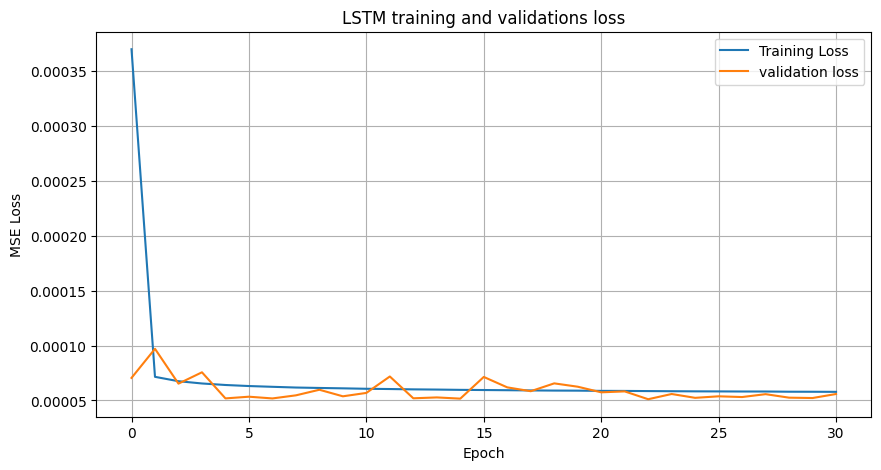

In [26]:
import matplotlib.pyplot as plt
plt.figure(figsize=( 10 ,5))
plt.plot(train_losses , label = "Training Loss")
plt.plot(val_losses , label = "validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("LSTM training and validations loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model.eval()
device = next(model.parameters()).device

predictions = []
with torch.no_grad():
    for xb, _ in test_loader:
        xb = xb.to(device)
        predictions.append(model(xb).cpu().numpy())

y_pred_scaled = np.concatenate(predictions, axis=0)

y_true = y_scaler.inverse_transform(y_test)
y_pred = y_scaler.inverse_transform(y_pred_scaled)

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
r2 = r2_score(y_true, y_pred)

print("Test MAE :", round(mae, 4))
print("Test RMSE:", round(rmse, 4))
print("Test R²  :", round(r2, 4))

Test MAE : 0.1021
Test RMSE: 0.7776
Test R²  : 0.9973


In [29]:
torch.save(
    model.state_dict() , "cpu_lstm_model.pth"
)
import joblib

joblib.dump(x_scaler, "cpu_feature_scaler.pkl")
joblib.dump(y_scaler, "cpu_target_scaler.pkl")


['cpu_target_scaler.pkl']